# Teste A/B da campanha

Comparar a taxa de conversão dos grupos A e B. Os pontos têm latitude e longitude,
mas o teste é sobre a conversão, não sobre o mapa.

Não há modelo para mandar à GPU. O conjunto é pequeno e o teste estatístico
já é vetorizado no SciPy.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats

ALFA = 0.05
df = pd.read_csv("dataset.csv")
print(df.shape)
print(df.groupby("grupo")["conversao"].mean())
df.head()

(1000, 5)
grupo
A    0.300000
B    0.315686
Name: conversao, dtype: float64


,usuario_id,grupo,latitude,longitude,conversao
0,1,A,35.669109,6.869443,1
1,2,B,6.497346,-7.494524,1
2,3,A,-34.285029,-170.768856,0
3,4,A,56.483104,-57.150782,1
4,5,A,33.251611,-43.129577,0


## Hipóteses

- H0: a conversão média de A e de B é a mesma.
- H1: as médias diferem.
- α = 0,05. Valor-p menor ou igual a α rejeita H0.

O teste t pede normalidade e variâncias parecidas. Conversão 0/1 não é uma
curva normal, então o Shapiro-Wilk deve rejeitar H0 de normalidade. O teste
de Levene olha se as variâncias são equivalentes. Se a normalidade falha,
a comparação que vale é o Mann-Whitney, que não pede distribuição normal.
O teste t fica no notebook para mostrar o contraste, não para decidir a campanha.

In [2]:
a = df.loc[df["grupo"] == "A", "conversao"]
b = df.loc[df["grupo"] == "B", "conversao"]

print("Shapiro A", stats.shapiro(a))
print("Shapiro B", stats.shapiro(b))
print("Levene", stats.levene(a, b))

t_stat, p_t = stats.ttest_ind(a, b)
u_stat, p_u = stats.mannwhitneyu(a, b)
print("t = %.3f  p = %.4f" % (t_stat, p_t))
print("U = %.3f  p = %.4f" % (u_stat, p_u))

if p_u <= ALFA:
    print("Mann-Whitney rejeita H0: a conversão difere entre A e B.")
else:
    print("Mann-Whitney não rejeita H0: não há diferença detectável na conversão.")

Shapiro A ShapiroResult(statistic=np.float64(0.5755484295691086), pvalue=np.float64(8.305357450336786e-33))
Shapiro B ShapiroResult(statistic=np.float64(0.585129503103347), pvalue=np.float64(4.39191381945773e-33))
Levene LeveneResult(statistic=np.float64(0.2880082452976037), pvalue=np.float64(0.5916193377766581))
t = -0.537  p = 0.5916
U = 122990.000  p = 0.5915
Mann-Whitney não rejeita H0: não há diferença detectável na conversão.


## Mapa

O gráfico só mostra onde estão os usuários de cada grupo. Ele não entra no teste.

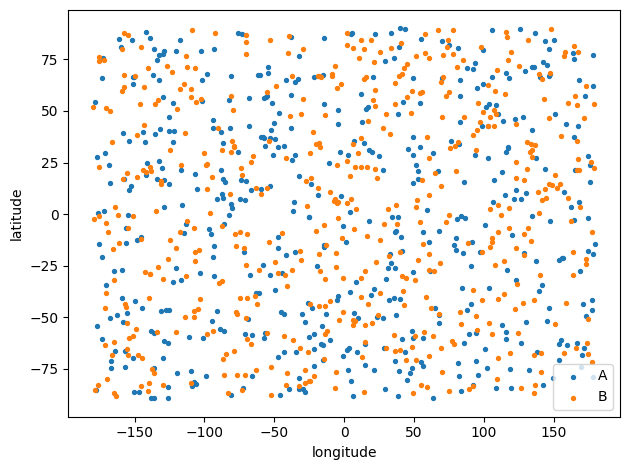

In [3]:
plt.scatter(df.loc[df.grupo == "A", "longitude"], df.loc[df.grupo == "A", "latitude"], s=8, label="A")
plt.scatter(df.loc[df.grupo == "B", "longitude"], df.loc[df.grupo == "B", "latitude"], s=8, label="B")
plt.xlabel("longitude")
plt.ylabel("latitude")
plt.legend()
plt.tight_layout()
plt.show()